In [1]:
import pandas as pd

research_df = pd.read_csv("research_articles_cleaned.csv")

display(research_df.head())

,Article,Content,Word Count,Cleaned Content,Cleaned Word Count,Reduction (%)
0,research_1.txt,The purposes of this article are to position m...,5602,purpose article position mixed method research...,3218,42.556230
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit...",2416,see researcher position reflexivity qualitativ...,1289,46.647351
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,3828,developmental research study instructional des...,2167,43.390805
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...,5922,abstract cronbach alpha statistic commonly quo...,3288,44.478217
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,4027,denzin paradigm shift revisiting triangulation...,2324,42.289546


In [2]:
# Import libraries for topic modelling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

print("LDA libraries imported successfully.")


LDA libraries imported successfully.


In [3]:
# Select the article names and cleaned content
lda_df = research_df[
    ["Article", "Cleaned Content"]
].copy()

# Remove missing or empty documents
lda_df = lda_df.dropna(
    subset=["Cleaned Content"]
)

lda_df = lda_df[
    lda_df["Cleaned Content"].str.strip() != ""
]

# Display the selected articles
print("Number of articles:", len(lda_df))

display(lda_df.head())


Number of articles: 5


,Article,Cleaned Content
0,research_1.txt,purpose article position mixed method research...
1,research_2.txt,see researcher position reflexivity qualitativ...
2,research_3.txt,developmental research study instructional des...
3,research_4.txt,abstract cronbach alpha statistic commonly quo...
4,research_5.txt,denzin paradigm shift revisiting triangulation...


In [4]:
# Create a word-frequency vectoriser
count_vectorizer = CountVectorizer(
    max_features=3000,
    min_df=1,
    max_df=0.95,
    ngram_range=(1, 1)
)

# Convert cleaned articles into word-count features
document_term_matrix = count_vectorizer.fit_transform(
    lda_df["Cleaned Content"]
)

# Extract the vocabulary
feature_names = count_vectorizer.get_feature_names_out()

# Display matrix information
print("Document-term matrix shape:", document_term_matrix.shape)
print("Number of vocabulary terms:", len(feature_names))
print("First 20 terms:", feature_names[:20])


Document-term matrix shape: (5, 2581)
Number of vocabulary terms: 2581
First 20 terms: ['aastrup' 'abbreviated' 'ability' 'able' 'abound' 'abraham' 'absence'
 'absent' 'abstract' 'abused' 'academia' 'academic' 'accent' 'accept'
 'acceptability' 'acceptable' 'acceptance' 'accepted' 'accepts' 'access']


In [5]:
# Define the number of research topics
number_of_topics = 3

# Initialise the LDA model
lda_model = LatentDirichletAllocation(
    n_components=number_of_topics,
    max_iter=100,
    learning_method="batch",
    random_state=42
)

# Train the model using the document-term matrix
lda_model.fit(document_term_matrix)

# Generate topic distributions for each article
document_topic_distribution = lda_model.transform(
    document_term_matrix
)

# Display model information
print("LDA model trained successfully.")
print("Number of topics:", number_of_topics)
print(
    "Document-topic distribution shape:",
    document_topic_distribution.shape
)

print("Model perplexity:", round(
    lda_model.perplexity(document_term_matrix), 4
))


LDA model trained successfully.
Number of topics: 3
Document-topic distribution shape: (5, 3)
Model perplexity: 1372.4422


In [6]:
# Define the number of important words per topic
number_of_words = 10

# Extract the top words and their probabilities
topic_word_results = []

for topic_index, topic_weights in enumerate(lda_model.components_):

    # Normalise word weights into probabilities
    topic_probabilities = (
        topic_weights / topic_weights.sum()
    )

    # Identify the highest-probability words
    top_word_indices = np.argsort(
        topic_probabilities
    )[-number_of_words:][::-1]

    # Store the words and their probabilities
    for word_index in top_word_indices:
        topic_word_results.append({
            "Topic": f"Topic {topic_index + 1}",
            "Word": feature_names[word_index],
            "Probability": topic_probabilities[word_index]
        })

# Create a DataFrame of topic keywords
topic_words_df = pd.DataFrame(topic_word_results)

# Display topic keywords
display(topic_words_df.round(4))


,Topic,Word,Probability
0,Topic 1,development,0.0317
1,Topic 1,developmental,0.0181
2,Topic 1,design,0.0173
3,Topic 1,instructional,0.0157
4,Topic 1,evaluation,0.0107
5,Topic 1,model,0.0075
6,Topic 1,product,0.0071
7,Topic 1,term,0.0056
8,Topic 1,orientation,0.0052
9,Topic 1,system,0.0052


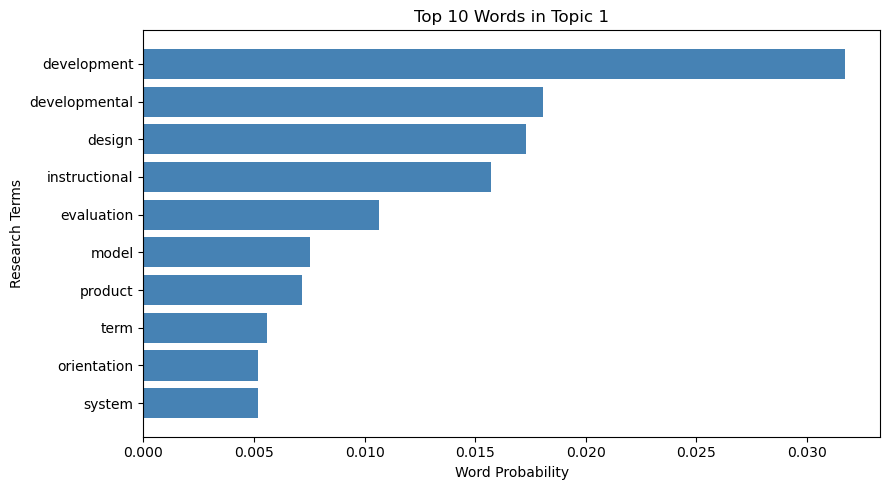

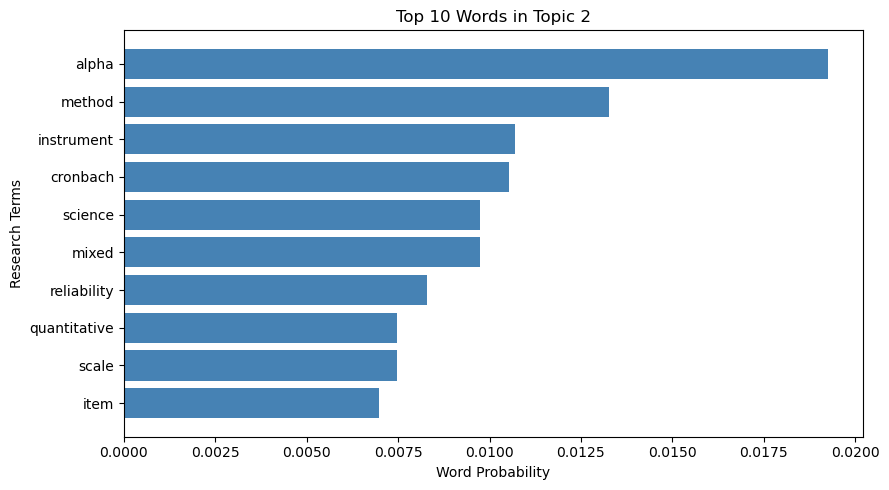

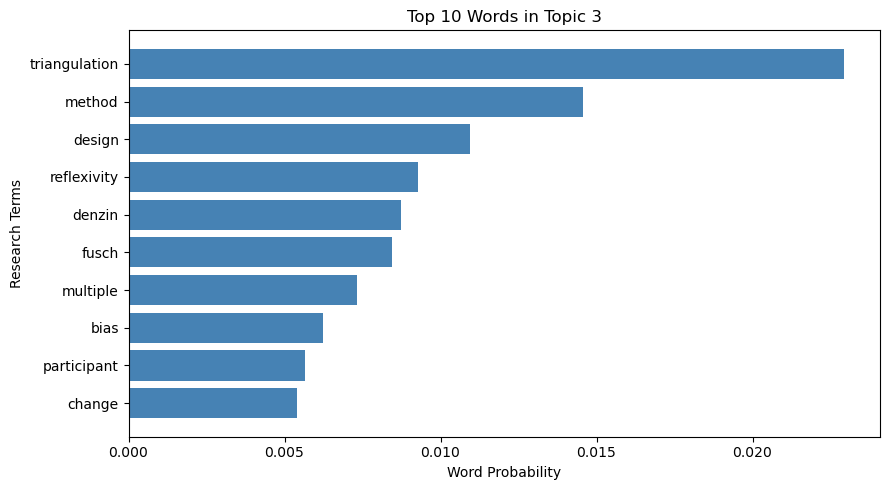

In [7]:
# Create a separate bar chart for each topic
for topic_number in range(1, number_of_topics + 1):

    # Select the words belonging to the current topic
    topic_data = topic_words_df[
        topic_words_df["Topic"] == f"Topic {topic_number}"
    ]

    # Create the horizontal bar chart
    plt.figure(figsize=(9, 5))

    plt.barh(
        topic_data["Word"],
        topic_data["Probability"],
        color="steelblue"
    )

    plt.gca().invert_yaxis()

    plt.title(f"Top 10 Words in Topic {topic_number}")
    plt.xlabel("Word Probability")
    plt.ylabel("Research Terms")

    plt.tight_layout()
    plt.show()


In [8]:
# Create topic column names
topic_columns = [
    f"Topic {topic_number}"
    for topic_number in range(1, number_of_topics + 1)
]

# Create a DataFrame of document-topic probabilities
topic_distribution_df = pd.DataFrame(
    document_topic_distribution,
    columns=topic_columns
)

# Add article names
topic_distribution_df.insert(
    0,
    "Article",
    lda_df["Article"].values
)

# Identify the dominant topic in each article
topic_distribution_df["Dominant Topic"] = [
    topic_columns[index]
    for index in np.argmax(
        document_topic_distribution,
        axis=1
    )
]

# Display the results
display(topic_distribution_df.round(4))


,Article,Topic 1,Topic 2,Topic 3,Dominant Topic
0,research_1.txt,0.0001,0.9997,0.0001,Topic 2
1,research_2.txt,0.0004,0.0004,0.9993,Topic 3
2,research_3.txt,0.9996,0.0002,0.0002,Topic 1
3,research_4.txt,0.0001,0.9997,0.0001,Topic 2
4,research_5.txt,0.0002,0.0002,0.9996,Topic 3


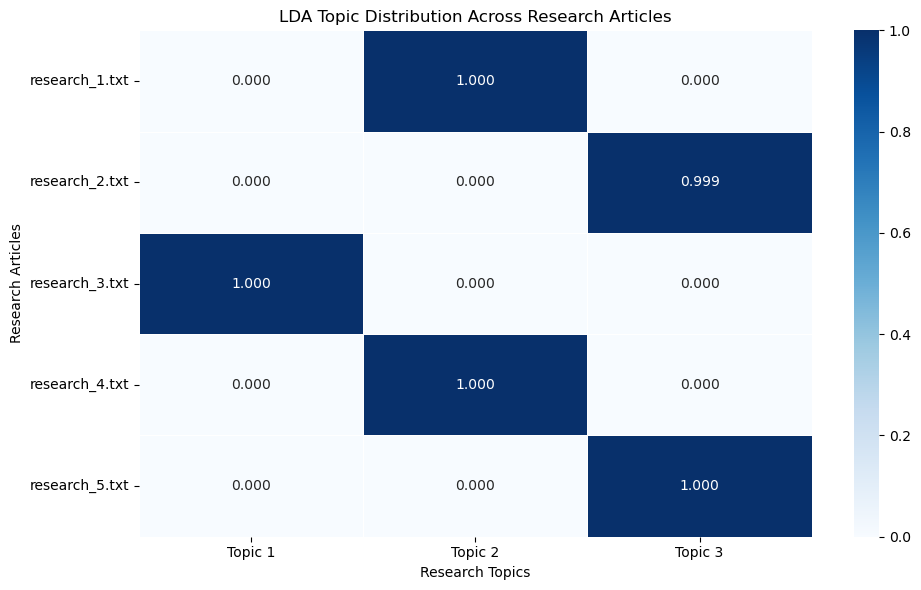

In [9]:
# Prepare the topic probabilities for visualisation
heatmap_data = topic_distribution_df.set_index(
    "Article"
)[topic_columns]

# Create a topic distribution heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("LDA Topic Distribution Across Research Articles")
plt.xlabel("Research Topics")
plt.ylabel("Research Articles")

plt.tight_layout()
plt.show()


,Topic,Average Probability
0,Topic 1,0.2001
1,Topic 2,0.4000
2,Topic 3,0.3999


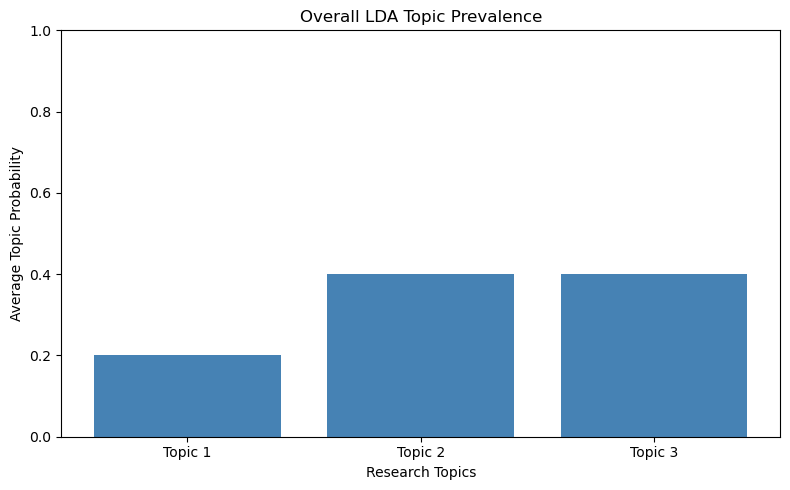

In [10]:
# Calculate average topic probabilities across all articles
average_topic_distribution = (
    document_topic_distribution.mean(axis=0)
)

# Create a DataFrame of overall topic prevalence
topic_prevalence_df = pd.DataFrame({
    "Topic": topic_columns,
    "Average Probability": average_topic_distribution
})

# Display the results
display(topic_prevalence_df.round(4))

# Visualise overall topic prevalence
plt.figure(figsize=(8, 5))

plt.bar(
    topic_prevalence_df["Topic"],
    topic_prevalence_df["Average Probability"],
    color="steelblue"
)

plt.title("Overall LDA Topic Prevalence")
plt.xlabel("Research Topics")
plt.ylabel("Average Topic Probability")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [14]:
# Evaluate LDA models with different numbers of topics
topic_results = []

for n_topics in range(2, 5):

    lda_test = LatentDirichletAllocation(
        n_components=n_topics,
        random_state=42,
        max_iter=20
    )

    lda_test.fit(document_term_matrix)

    topic_results.append({
        "Number of Topics": n_topics,
        "Perplexity": lda_test.perplexity(document_term_matrix)
    })

topic_evaluation = pd.DataFrame(topic_results)

display(topic_evaluation)



,Number of Topics,Perplexity
0,2,1478.373271
1,3,1372.442173
2,4,1362.506118


## LDA Model Evaluation and Topic Selection

Latent Dirichlet Allocation (LDA) models containing two, three and four topics were evaluated using perplexity scores. The results showed that perplexity decreased from 1478.7373 for two topics to 1372.4422 for three topics and 1362.5061 for four topics.

Although the four-topic model achieved the lowest perplexity, the three-topic model was retained provisionally because it produced interpretable research themes, including developmental research, research methodology and triangulation.

The relatively small improvement in perplexity between three and four topics suggests that additional topics may offer limited benefit. However, further evaluation of topic coherence and interpretability would be necessary to confirm the most suitable configuration.

Since the analysis used only five research articles and perplexity was measured on the training corpus, the findings should be interpreted cautiously.

In [16]:
# 4.2

%pip install pyLDAvis


   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.6 MB 1.4 MB/s eta 0:00:02
   ---------------- ----------------------- 1.0/2.6 MB 1.6 MB/s eta 0:00:01
   -------------------- ------------------- 1.3/2.6 MB 1.6 MB/s eta 0:00:01
   ---------------------------- ----------- 1.8/2.6 MB 1.7 MB/s eta 0:00:01
   -------------------------------- ------- 2.1/2.6 MB 1.7 MB/s eta 0:00:01
   ------------------------------------ --- 2.4/2.6 MB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 2.6/2.6 MB 1.7 MB/s  0:00:01
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
    --------------------------------------- 0.5/24.4 MB 1.9 MB/s eta 0:00:13
   - -------------------------------------- 0.8/24.4 MB 1.8 MB/s eta 0:00:14
   - ----------------------------------

In [17]:

# Import libraries for interactive LDA visualisation
import pyLDAvis
import pyLDAvis.lda_model

print("pyLDAvis libraries imported successfully.")


pyLDAvis libraries imported successfully.


In [20]:
# Prepare interactive topic visualisation
lda_visualisation = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    count_vectorizer,
    sort_topics=False
)

# Display the interactive map in Jupyter
pyLDAvis.display(lda_visualisation)


In [21]:
# Save interactive visualisation as HTML
pyLDAvis.save_html(
    lda_visualisation,
    "LDA_Intertopic_Distance_Map.html"
)

print("Interactive LDA map saved successfully.")


Interactive LDA map saved successfully.


### 4.2 Interactive Intertopic Distance Visualisation

An interactive topic visualisation was developed using the pyLDAvis library to examine the three topics identified by the Latent Dirichlet Allocation (LDA) model.

The Intertopic Distance Map represents topics as circles, with their relative sizes indicating topic prevalence and the distances between them reflecting differences in their word distributions.

The interactive visualisation also displays the most relevant terms associated with each topic, supporting the interpretation and comparison of the identified research themes. The visualisation was exported as an HTML file for interactive viewing and inclusion in the project repository.